In [ ]:
import os

def create_project_structure():
    # Имя главной папки проекта
    base_dir = "hackathon_ai"

    # Список всех папок, которые нужно создать
    # os.path.join используется для кроссплатформенности (Windows/Linux/Mac)
    directories = [
        os.path.join(base_dir, "dataset", "images", "train"),
        os.path.join(base_dir, "dataset", "images", "val"),
        os.path.join(base_dir, "dataset", "labels", "train"),
        os.path.join(base_dir, "dataset", "labels", "val"),
        os.path.join(base_dir, "weights"),
    ]

    # 1. Создаем папки
    for dir_path in directories:
        os.makedirs(dir_path, exist_ok=True)
    print(f"✅ Структура папок успешно создана в директории: {base_dir}")

    # 2. Создаем файл конфигурации data.yaml
    # ВАЖНО: Если вы размечали другое количество классов, измените nc и names
    yaml_content = """# Конфигурация датасета для YOLOv8
path: ./dataset
train: images/train
val: images/val

# Количество классов (зависит от вашей разметки)
nc: 7

# Названия классов (строго в том порядке, в котором их выдал Roboflow!)
names: ['foundation', 'walls', 'roof_frame', 'roof_finished', 'windows', 'doors', 'fence']
"""
    with open(os.path.join(base_dir, "data.yaml"), "w", encoding="utf-8") as f:
        f.write(yaml_content)
    print("✅ Файл data.yaml создан.")

    # 3. Создаем скрипт обучения train.py
    train_content = """from ultralytics import YOLO

def main():
    # Загружаем базовую модель (скачается автоматически при первом запуске)
    model = YOLO('yolov8n.pt')

    # Запускаем обучение
    model.train(
        data='data.yaml',
        epochs=50,
        imgsz=640,
        batch=16,
        name='drone_model',
        device=0 # 0 - если есть GPU, 'cpu' - если только процессор
    )

if __name__ == '__main__':
    main()
"""
    with open(os.path.join(base_dir, "train.py"), "w", encoding="utf-8") as f:
        f.write(train_content)
    print("✅ Файл train.py создан.")

    # 4. Создаем скрипт для работы AI-агента predict.py
    predict_content = """from ultralytics import YOLO

def analyze_construction(image_path):
    # Загружаем НАШУ обученную модель (появится после запуска train.py)
    model = YOLO('runs/detect/drone_model/weights/best.pt')

    # Делаем предсказание
    results = model(image_path)

    # Извлекаем найденные классы
    detected_classes = []
    for result in results:
        for box in result.boxes:
            class_id = int(box.cls[0])
            class_name = model.names[class_id]
            detected_classes.append(class_name)

    detected_classes = list(set(detected_classes))

    # БИЗНЕС-ЛОГИКА БАНКА
    stage = 0
    if 'foundation' in detected_classes or 'walls' in detected_classes:
        stage = 50
    if 'windows' in detected_classes and ('roof_finished' in detected_classes or 'doors' in detected_classes):
        stage = 100

    print(f"--- АНАЛИЗ ОБЪЕКТА ---")
    print(f"Стадия готовности: {stage}%")
    print(f"Найдены элементы: {', '.join(detected_classes)}")

    # Сохраняем картинку с нарисованными рамками (для защиты)
    results[0].save(filename='result_with_boxes.jpg')
    print("Визуализация сохранена в result_with_boxes.jpg")

if __name__ == '__main__':
    # Укажите путь к тестовой картинке
    test_image = 'dataset/images/val/ваша_картинка.jpg'
    # analyze_construction(test_image)
    print("Раскомментируйте вызов analyze_construction и укажите путь к фото.")
"""
    with open(os.path.join(base_dir, "predict.py"), "w", encoding="utf-8") as f:
        f.write(predict_content)
    print("✅ Файл predict.py создан.")

    print("\n🚀 Всё готово! Переходите в папку hackathon_ai и начинайте работать.")

if __name__ == "__main__":
    create_project_structure()

: 

In [ ]:
import os
import shutil
import zipfile
from google.colab import files

# 1. Запрос файла
print("Выберите ваш ZIP-архив из Roboflow (который вы скачали):")
uploaded = files.upload()

# 2. Распаковка
for filename in uploaded.keys():
    print(f"Распаковка {filename}...")
    with zipfile.ZipFile(filename, 'r') as zip_ref:
        zip_ref.extractall("temp_data")

# 3. Перенос файлов в структуру hackathon_ai
base_src = "temp_data/train"
base_dst = "hackathon_ai/dataset"

# Переносим картинки train
if os.path.exists(f"{base_src}/images"):
    for file in os.listdir(f"{base_src}/images"):
        shutil.move(f"{base_src}/images/{file}", f"{base_dst}/images/train/")

# Переносим тексты train
if os.path.exists(f"{base_src}/labels"):
    for file in os.listdir(f"{base_src}/labels"):
        shutil.move(f"{base_src}/labels/{file}", f"{base_dst}/labels/train/")

# Переносим картинки val (если есть)
val_src = "temp_data/valid"
if os.path.exists(val_src):
    if os.path.exists(f"{val_src}/images"):
        for file in os.listdir(f"{val_src}/images"):
            shutil.move(f"{val_src}/images/{file}", f"{base_dst}/images/val/")
    if os.path.exists(f"{val_src}/labels"):
        for file in os.listdir(f"{val_src}/labels"):
            shutil.move(f"{val_src}/labels/{file}", f"{base_dst}/labels/val/")

print("✅ Данные успешно загружены и разложены по папкам!")

Выберите ваш ZIP-архив из Roboflow (который вы скачали):


Saving hackaton sber.v1i.yolov8.zip to hackaton sber.v1i.yolov8.zip
Распаковка hackaton sber.v1i.yolov8.zip...
✅ Данные успешно загружены и разложены по папкам!


In [ ]:
# Устанавливаем библиотеку
!pip install ultralytics -q

# Запускаем обучение
!yolo task=detect mode=train model=yolov8n.pt data=hackathon_ai/data.yaml epochs=50 imgsz=640 batch=16

Ultralytics 8.4.194 🚀 Python-3.13.18 torch-2.11.0+cpu CPU (AMD EPYC 7B12)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=hackathon_ai/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-3, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overla

In [ ]:
import os
import shutil
import random

# Пути к папкам
train_images_dir = "/content/hackathon_ai/dataset/images/train"
train_labels_dir = "/content/hackathon_ai/dataset/labels/train"
val_images_dir = "/content/hackathon_ai/dataset/images/val"
val_labels_dir = "/content/hackathon_ai/dataset/labels/val"

# Создаем папки для валидации, если их нет
os.makedirs(val_images_dir, exist_ok=True)
os.makedirs(val_labels_dir, exist_ok=True)

# Получаем список всех изображений
all_images = [f for f in os.listdir(train_images_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]

# Перемешиваем и берем 10 изображений (20% от 50)
random.shuffle(all_images)
val_images = all_images[:10]

# Копируем изображения и соответствующие им .txt файлы
for img_name in val_images:
    # Копируем изображение
    shutil.copy(os.path.join(train_images_dir, img_name), os.path.join(val_images_dir, img_name))

    # Копируем файл разметки
    base_name = os.path.splitext(img_name)[0]
    label_name = base_name + ".txt"
    if os.path.exists(os.path.join(train_labels_dir, label_name)):
        shutil.copy(os.path.join(train_labels_dir, label_name), os.path.join(val_labels_dir, label_name))

print(f"✅ Скопировано {len(val_images)} изображений и их разметок в папку валидации.")

✅ Скопировано 10 изображений и их разметок в папку валидации.


Анализируем: /content/hackathon_ai/dataset/images/val/DJI_20260807164911_0005_D_JPG.rf.9b75f901d1ed4c02fa7b64b6859cc48e.jpg

image 1/1 /content/hackathon_ai/dataset/images/val/DJI_20260807164911_0005_D_JPG.rf.9b75f901d1ed4c02fa7b64b6859cc48e.jpg: 640x640 3 wallss, 1 roof_frame, 1 roof_finished, 1 windows, 1 doors, 132.5ms
Speed: 2.6ms preprocess, 132.5ms inference, 0.6ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict-3

РЕЗУЛЬТАТ РАБОТЫ AI-АГЕНТА (VISION)
Найдено на снимке: windows, roof_frame, doors, walls, roof_finished
ОПРЕДЕЛЕННАЯ СТАДИЯ: 100%


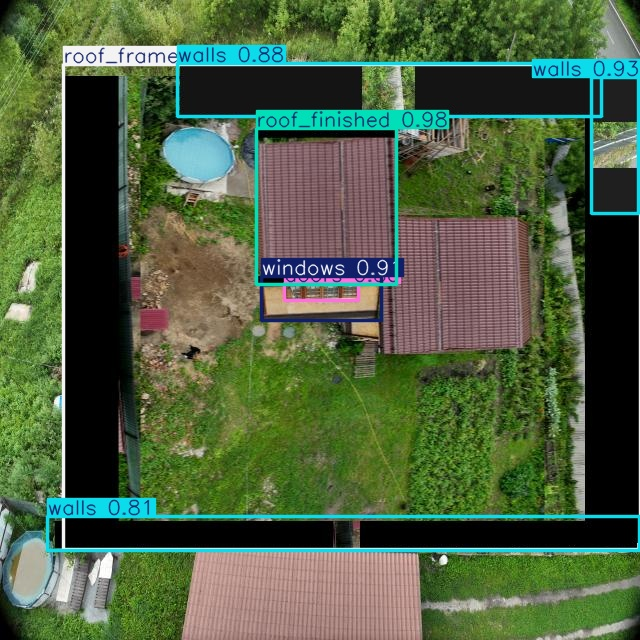

In [ ]:
from ultralytics import YOLO
import os
from IPython.display import Image, display

# 1. Загружаем нашу обученную модель
model = YOLO('/content/runs/detect/train-3/weights/best.pt')

# 2. Берем случайное фото из папки валидации
val_dir = '/content/hackathon_ai/dataset/images/val'
test_image = os.path.join(val_dir, os.listdir(val_dir)[0])

print(f"Анализируем: {test_image}")

# 3. Запускаем предсказание (сохраняем картинку с рамками)
results = model.predict(test_image, conf=0.4, save=True)

# 4. Бизнес-логика для хакатона (Пункт 2 из кейса)
detected_classes = []
for r in results:
    for c in r.boxes.cls:
        detected_classes.append(model.names[int(c)])
detected_classes = list(set(detected_classes)) # убираем дубликаты

stage = 0
if 'foundation' in detected_classes or 'walls' in detected_classes:
    stage = 50
if 'windows' in detected_classes or 'doors' in detected_classes or 'roof_finished' in detected_classes:
    stage = 100

print("\n" + "="*40)
print("РЕЗУЛЬТАТ РАБОТЫ AI-АГЕНТА (VISION)")
print("="*40)
print(f"Найдено на снимке: {', '.join(detected_classes)}")
print(f"ОПРЕДЕЛЕННАЯ СТАДИЯ: {stage}%")
print("="*40)

# 5. Показываем картинку прямо в Colab
save_dir = '/content/runs/detect/predict'
last_saved_img = os.path.join(save_dir, os.listdir(save_dir)[-1])
display(Image(filename=last_saved_img, width=800))

In [ ]:
import os
print(os.path.abspath("hackathon_ai/dataset"))

/content/hackathon_ai/dataset


In [ ]:
import yaml

# Вставьте сюда путь, который вы скопировали на предыдущем шаге
absolute_path = "/content/hackathon_ai/dataset"

yaml_path = "hackathon_ai/data.yaml"
with open(yaml_path, 'r') as f:
    data = yaml.safe_load(f)

# Заменяем относительный путь на абсолютный
data['path'] = absolute_path

with open(yaml_path, 'w') as f:
    yaml.dump(data, f, default_flow_style=False)

print(f"✅ Путь в {yaml_path} успешно обновлён на: {absolute_path}")

✅ Путь в hackathon_ai/data.yaml успешно обновлён на: /content/hackathon_ai/dataset



image 1/1 /content/hackathon_ai/dataset/images/val/DJI_20260807164911_0005_D_JPG.rf.9b75f901d1ed4c02fa7b64b6859cc48e.jpg: 640x640 3 wallss, 1 roof_frame, 1 roof_finished, 1 windows, 1 doors, 129.8ms
Speed: 2.5ms preprocess, 129.8ms inference, 0.6ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict-4

📸 Анализ картинки: DJI_20260807164911_0005_D_JPG.rf.9b75f901d1ed4c02fa7b64b6859cc48e.jpg


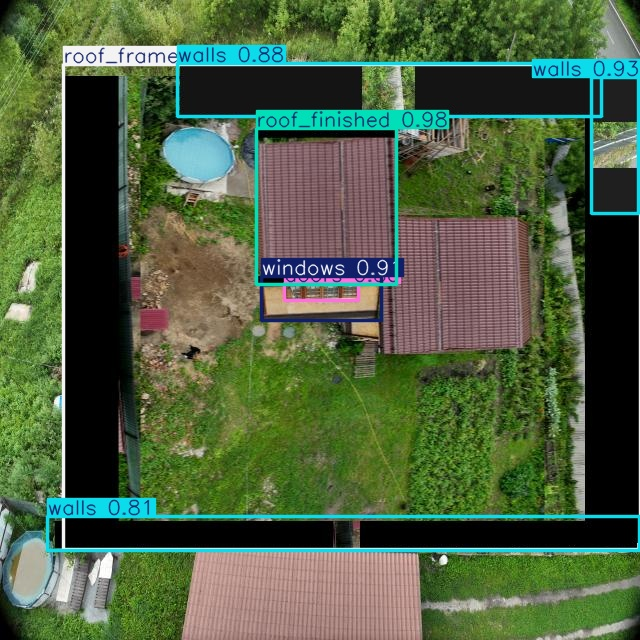


image 1/1 /content/hackathon_ai/dataset/images/val/DJI_20260807184641_0003_D_JPG.rf.0c97e9796bda1c3590b1953f54937622.jpg: 640x640 1 foundation, 1 roof_finished, 137.5ms
Speed: 3.3ms preprocess, 137.5ms inference, 0.8ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict-4

📸 Анализ картинки: DJI_20260807184641_0003_D_JPG.rf.0c97e9796bda1c3590b1953f54937622.jpg


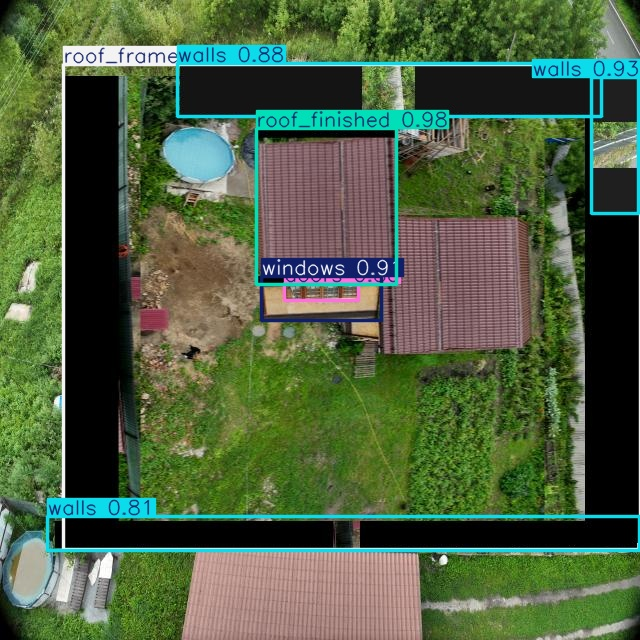


image 1/1 /content/hackathon_ai/dataset/images/val/DJI_20260807184706_0006_D_JPG.rf.2151bf2fb0b071479aabce71d49c2481.jpg: 640x640 1 foundation, 1 roof_finished, 1 windows, 1 doors, 145.8ms
Speed: 2.0ms preprocess, 145.8ms inference, 0.7ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict-4

📸 Анализ картинки: DJI_20260807184706_0006_D_JPG.rf.2151bf2fb0b071479aabce71d49c2481.jpg


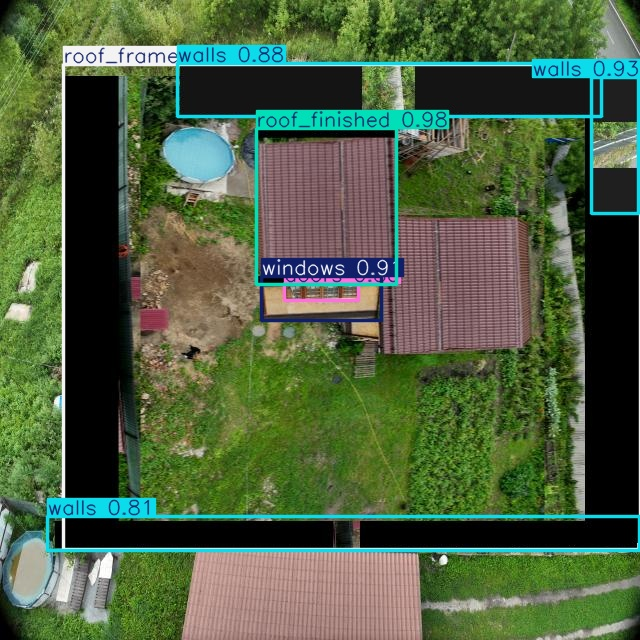

In [ ]:
from ultralytics import YOLO
import os
from IPython.display import Image, display

# 1. Загружаем нашу модель
model = YOLO('/content/runs/detect/train-3/weights/best.pt')

# 2. Берем папку с картинками
val_dir = '/content/hackathon_ai/dataset/images/val'
all_images = [f for f in os.listdir(val_dir) if f.endswith('.jpg')]

# 3. Берем 3 картинки (или меньше, если их всего 2)
images_to_check = all_images[:3]

for img_name in images_to_check:
    img_path = os.path.join(val_dir, img_name)

    # Делаем предсказание (save=True сохранит картинку с рамками)
    results = model.predict(img_path, conf=0.4, save=True)

    print(f"\n📸 Анализ картинки: {img_name}")

    # Находим, куда сохранилась картинка с рамками, и показываем её
    save_dir = '/content/runs/detect/predict'
    # YOLO сохраняет файл с тем же именем
    saved_img_path = os.path.join(save_dir, img_name)

    # Если по какой-то причине имя изменилось, берем последнюю сохраненную
    if not os.path.exists(saved_img_path):
        saved_img_path = os.path.join(save_dir, os.listdir(save_dir)[-1])

    display(Image(filename=saved_img_path, width=600))

Выберите картинку с компьютера (JPG):


Saving гш.jpg to гш.jpg
Анализируем ваш файл: гш.jpg

image 1/1 /content/гш.jpg: 480x640 1 roof_finished, 133.2ms
Speed: 2.8ms preprocess, 133.2ms inference, 1.8ms postprocess per image at shape (1, 3, 480, 640)
Results saved to /content/runs/detect/predict-15
Найдено: ['roof_finished'] -> Стадия: 0%


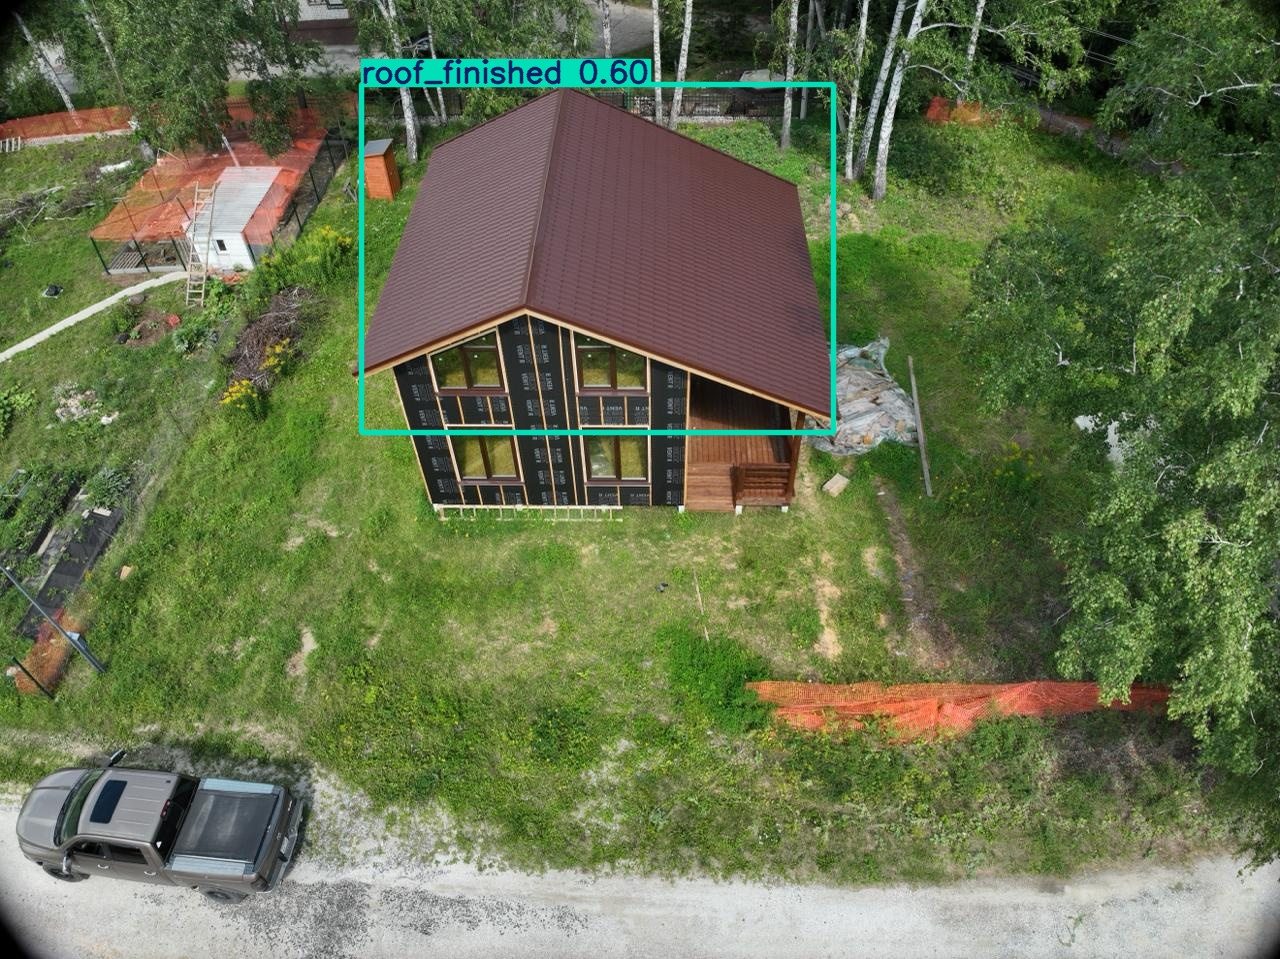

In [ ]:
from ultralytics import YOLO
from google.colab import files
from IPython.display import Image, display
import os

# 1. Загружаем модель
model = YOLO('/content/runs/detect/train-3/weights/best.pt')

# 2. Просим загрузить файл
print("Выберите картинку с компьютера (JPG):")
uploaded = files.upload()

# 3. Обрабатываем загруженный файл
for filename in uploaded.keys():
    print(f"Анализируем ваш файл: {filename}")
    results = model.predict(filename, conf=0.4, save=True)

    # БИЗНЕС-ЛОГИКА (выводим стадию)
    detected_classes = [model.names[int(c)] for r in results for c in r.boxes.cls]
    detected_classes = list(set(detected_classes))

    stage = 0
    if 'foundation' in detected_classes or 'walls' in detected_classes:
        stage = 50
    if 'windows' in detected_classes and ('roof_finished' in detected_classes or 'doors' in detected_classes):
        stage = 100

    print(f"Найдено: {detected_classes} -> Стадия: {stage}%")

    # БЕРЕМ ПУТЬ НАПРЯМУЮ ИЗ РЕЗУЛЬТАТА (самый надежный способ!)
    actual_save_dir = results[0].save_dir
    saved_img_path = os.path.join(actual_save_dir, filename)

    # Показываем результат
    display(Image(filename=saved_img_path, width=800))

In [ ]:
from ultralytics import YOLO
import os

# Загружаем модель
model = YOLO('/content/runs/detect/train-3/weights/best.pt')

def run_ai_pipeline(image_path, overdue_days, forecast_delay_days):
    print(f"🔍 1. Анализ снимка: {os.path.basename(image_path)}")

    # --- ЧАСТЬ 1: AI-АГЕНТ (VISION) ---
    results = model.predict(image_path, conf=0.4, verbose=False)

    detected_classes = [model.names[int(c)] for r in results for c in r.boxes.cls]
    detected_classes = list(set(detected_classes))

    stage = 0
    if 'foundation' in detected_classes or 'walls' in detected_classes:
        stage = 50
    if 'windows' in detected_classes and ('roof_finished' in detected_classes or 'doors' in detected_classes):
        stage = 100

    print(f"   ✅ Найдено: {', '.join(detected_classes)}")
    print(f"   ✅ Стадия готовности: {stage}%")

    # --- ЧАСТЬ 2: AI-ДИРИЖЕР (DECISION) ---
    print(f"🧠 2. Принятие решения (Просрочка: {overdue_days} дн., Задержка стройки: {forecast_delay_days} дн.)")

    strategy = ""
    reason = ""

    if stage == 100 and overdue_days > 30:
        strategy = "Передача дела в суд / Взыскание"
        reason = "Объект достроен (100%), но клиент имеет длительную просрочку. Залог можно реализовать."
    elif stage <= 50 and forecast_delay_days > 60:
        strategy = "Выдача доп. транша под контроль"
        reason = "Стройка встала на этапе 50%. Выдача средств поможет завершить объект."
    elif stage == 50 and 0 < overdue_days <= 30:
        strategy = "Кредитные каникулы"
        reason = "Временные трудности клиента на фоне строительства. Даем время."
    elif stage == 0 and overdue_days > 90:
        strategy = "Взыскание / Продажа участка"
        reason = "Строительство не начато, длительная просрочка."
    else:
        strategy = "Стандартный мониторинг"
        reason = "Рисков не выявлено, строительство идет по графику."

    print(f"   👉 РЕШЕНИЕ: {strategy}")
    print(f"   📝 ОБОСНОВАНИЕ: {reason}\n")
    return stage, strategy

# ТЕСТИРУЕМ НА ЛЮБОЙ КАРТИНКЕ
val_dir = '/content/hackathon_ai/dataset/images/val'
test_image = os.path.join(val_dir, os.listdir(val_dir)[0])

# Симулируем данные: у клиента просрочка 45 дней, задержка прогноза 10 дней
run_ai_pipeline(test_image, overdue_days=45, forecast_delay_days=10)

🔍 1. Анализ снимка: DJI_20260807164911_0005_D_JPG.rf.9b75f901d1ed4c02fa7b64b6859cc48e.jpg
   ✅ Найдено: windows, roof_frame, doors, walls, roof_finished
   ✅ Стадия готовности: 100%
🧠 2. Принятие решения (Просрочка: 45 дн., Задержка стройки: 10 дн.)
   👉 РЕШЕНИЕ: Передача дела в суд / Взыскание
   📝 ОБОСНОВАНИЕ: Объект достроен (100%), но клиент имеет длительную просрочку. Залог можно реализовать.



(100, 'Передача дела в суд / Взыскание')

In [ ]:
!pip install gradio -q

import gradio as gr
from ultralytics import YOLO
import os

model = YOLO('/content/runs/detect/train-3/weights/best.pt')

def process_uploaded_photo(image, overdue, delay):
    # Сохраняем загруженное фото
    img_path = "temp_upload.jpg"
    image.save(img_path)

    # Анализ
    results = model.predict(img_path, conf=0.4, save=True, verbose=False)
    detected_classes = [model.names[int(c)] for r in results for c in r.boxes.cls]
    detected_classes = list(set(detected_classes))

    stage = 0
    if 'foundation' in detected_classes or 'walls' in detected_classes: stage = 50
    if 'windows' in detected_classes and ('roof_finished' in detected_classes or 'doors' in detected_classes): stage = 100

    # Логика дирижера
    if stage == 100 and overdue > 30:
        strategy = "Передача дела в суд / Взыскание"; reason = "Объект достроен, есть просрочка."
    elif stage <= 50 and delay > 60:
        strategy = "Доп. финансирование"; reason = "Стройка встала, нужен транш."
    elif stage == 50 and 0 < overdue <= 30:
        strategy = "Кредитные каникулы"; reason = "Временные трудности."
    else:
        strategy = "Стандартный мониторинг"; reason = "Рисков не выявлено."

    # Находим картинку с рамками
    save_dir = results[0].save_dir
    saved_img_path = os.path.join(save_dir, "temp_upload.jpg")

    report = f"### Результат анализа\n"
    report += f"**Стадия готовности:** {stage}%\n\n"
    report += f"**Найденные элементы:** {', '.join(detected_classes)}\n\n"
    report += f"**Стратегия банка:** {strategy}\n\n"
    report += f"**Обоснование:** {reason}\n"

    return saved_img_path, report

# Создаем интерфейс
interface = gr.Interface(
    fn=process_uploaded_photo,
    inputs=[
        gr.Image(type="pil", label="Загрузите аэрофотоснимок"),
        gr.Slider(0, 180, value=0, label="Просрочка по кредиту (дней)"),
        gr.Slider(0, 180, value=0, label="Прогноз задержки стройки (дней)")
    ],
    outputs=[
        gr.Image(label="Разметка AI-агента"),
        gr.Markdown(label="Отчет AI-дирижера")
    ],
    title="AI-Мониторинг ИЖС",
    description="Загрузите фото с дрона и укажите данные кредитного контура."
)

interface.launch(debug=True)

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://f822a932758f0f56b6.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Results saved to /content/runs/detect/predict-16
Results saved to /content/runs/detect/predict-16
Results saved to /content/runs/detect/predict-16
Results saved to /content/runs/detect/predict-16
Results saved to /content/runs/detect/predict-16
Results saved to /content/runs/detect/predict-16
Results saved to /content/runs/detect/predict-16
Results saved to /content/runs/detect/predict-16
Results saved to /content/runs/detect/predict-16
Results saved to /content/runs/detect/predict-16
Results saved to /content/runs/detect/predict-16
Results saved to /content/runs/detect/predict-16
Results saved to /content/runs/detect/predict-16
Results saved to /content/runs/detect/predict-16
Results saved to /content/runs/detect/predict-16
Results saved to /content/runs/detect/predict-16
Results saved to /content/runs/detect/predict-16
Results saved to /content/runs/detect/predict-16
Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://f822a932758f0f56b6.gr

In [ ]:
# Устанавливаем библиотеку (если еще не установлена)
!pip install gradio -q

import gradio as gr
from ultralytics import YOLO
import os

# Загружаем вашу обученную модель
# Убедитесь, что путь к best.pt правильный!
model = YOLO('/content/runs/detect/train-3/weights/best.pt')

def process_uploaded_photo(image, overdue, delay):
    if image is None:
        return None, "Ошибка: Загрузите изображение."

    # Сохраняем загруженное фото во временный файл
    img_path = "temp_upload.jpg"
    image.save(img_path)

    # 1. AI-АГЕНТ (VISION)
    results = model.predict(img_path, conf=0.4, save=True, verbose=False)

    detected_classes = []
    for r in results:
        for c in r.boxes.cls:
            detected_classes.append(model.names[int(c)])
    detected_classes = list(set(detected_classes)) # Убираем дубликаты

    # 2. БИЗНЕС-ЛОГИКА ОПРЕДЕЛЕНИЯ СТАДИИ
    stage = 0

    # Если есть фундамент или стены, но нет крыши - это 50%
    if 'foundation' in detected_classes or 'walls' in detected_classes:
        stage = 50

    # Если модель нашла готовую крышу, окна или двери - объект готов на 100%
    # (Даже если окон не видно сверху, готовая крыша означает завершение коробки)
    if 'roof_finished' in detected_classes or 'windows' in detected_classes or 'doors' in detected_classes:
        stage = 100

    # 3. AI-ДИРИЖЕР (DECISION)
    if stage == 100 and overdue > 30:
        strategy = "Передача дела в суд / Взыскание"
        reason = "Объект достроен (100%), но клиент имеет длительную просрочку."
    elif stage <= 50 and delay > 60:
        strategy = "Выдача доп. транша под контроль"
        reason = "Стройка встала на этапе 50%. Выдача средств поможет завершить объект."
    elif stage == 50 and 0 < overdue <= 30:
        strategy = "Кредитные каникулы"
        reason = "Временные трудности клиента на фоне строительства. Даем время."
    elif stage == 0 and overdue > 90:
        strategy = "Взыскание / Продажа участка"
        reason = "Строительство не начато, длительная просрочка."
    else:
        strategy = "Стандартный мониторинг"
        reason = "Рисков не выявлено, строительство идет по графику."

    # 4. ФОРМИРОВАНИЕ ОТЧЕТА
    save_dir = results[0].save_dir
    saved_img_path = os.path.join(save_dir, "temp_upload.jpg")

    # Если YOLO переименовал файл, берем последний сохраненный
    if not os.path.exists(saved_img_path):
         saved_img_path = os.path.join(save_dir, os.listdir(save_dir)[-1])

    report = f"### Результат анализа\n"
    report += f"**Стадия готовности:** {stage}%\n\n"
    report += f"**Найденные элементы:** {', '.join(detected_classes) if detected_classes else 'Ничего не найдено'}\n\n"
    report += f"**Стратегия банка:** {strategy}\n\n"
    report += f"**Обоснование:** {reason}\n"

    return saved_img_path, report

# --- СОЗДАНИЕ ИНТЕРФЕЙСА ---
interface = gr.Interface(
    fn=process_uploaded_photo,
    inputs=[
        gr.Image(type="pil", label="Загрузите аэрофотоснимок (JPG)"),
        gr.Slider(0, 180, value=0, step=1, label="Просрочка по кредиту (дней)"),
        gr.Slider(0, 180, value=0, step=1, label="Прогноз задержки стройки (дней)")
    ],
    outputs=[
        gr.Image(label="Разметка AI-агента (Vision)"),
        gr.Markdown(label="Отчет AI-дирижера (Decision)")
    ],
    title="🛰️ AI-Мониторинг объектов ИЖС",
    description="Прототип системы автоматической оценки залогов. Загрузите снимок с дрона и укажите данные кредитного контура."
)

# Запуск (появится ссылка, по которой нужно кликнуть)
interface.launch(debug=True)

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://0b13b4f2c49a074b96.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Results saved to /content/runs/detect/predict-17
Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://0b13b4f2c49a074b96.gradio.live
